# 05 - Post-Training: Instruction Fine-Tuning and RLHF

## Imports

In [1]:
import warnings
# Same known benign numpy 2.x + Apple Accelerate BLAS quirk as the earlier notebooks
warnings.filterwarnings('ignore', category=RuntimeWarning)

import numpy as np
import matplotlib.pyplot as plt

# Make sure we get the same outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)

## What's Missing So Far

`04-generation-and-why-chat-models-behave.ipynb` ended with a short claim about how next-token prediction alone produces a model that *continues* text, and a second training stage is what turns it into an assistant that *answers*. It named the two techniques behind that stage, **instruction fine-tuning** and **RLHF**.

This notebook builds both, at toy scale. The same three-step arc holds for production-level systems: pretrain a continuer, fine-tune it to answer, then use preference feedback to steer which answers it gives.

## The Setup: A Toy Language With Statements and Questions

The vocabulary is twelve tokens. Four of them are *special* tokens. `<pad>` fills the empty space before a document starts, `<end>` marks where a response (or document) stops, and `<bot>` is a role marker that a **chat template** inserts to say "the assistant's turn starts here." The model only ever sees the last `CONTEXT_SIZE = 5` tokens, exactly like `04`'s word predictor, just with a longer window so a question is still in view while its answer is being written.

The pretraining corpus plays the role of "raw text from the internet". Nothing in it is a question followed by an answer.

In [2]:
VERBS = ["climbs", "scores", "defends"]
vocabulary = ["<pad>", "<end>", "<bot>", "the", "robot", "wall", "then", "what", "?"] + VERBS
word_to_id = {word: i for i, word in enumerate(vocabulary)}
vocab_size = len(vocabulary)
CONTEXT_SIZE = 5

def one_hot(word_id, size):
    vector = np.zeros(size)
    vector[word_id] = 1.0
    return vector

def encode(context_words):
    return np.concatenate([one_hot(word_to_id[w], vocab_size) for w in context_words])

def make_examples(documents, response_only=False):
    # Slide a window over each document (left-padded so even the first token gets predicted).
    # A mask marks which targets count toward the loss: all of them for pretraining, but only
    # the tokens after <bot> for fine-tuning (the model shouldn't be graded on writing the question).
    inputs, targets, mask = [], [], []
    for doc in documents:
        padded = ["<pad>"] * CONTEXT_SIZE + doc
        first_graded = doc.index("<bot>") + 1 if response_only else 0
        for j in range(len(doc)):
            inputs.append(encode(padded[j:j + CONTEXT_SIZE]))
            targets.append(word_to_id[doc[j]])
            mask.append(1.0 if j >= first_graded else 0.0)
    return np.array(inputs).T, np.array(targets), np.array(mask)

pretraining_docs = []
for _ in range(100):
    pretraining_docs.append("the robot climbs the wall then scores <end>".split())
    pretraining_docs.append("the robot defends then the robot scores <end>".split())
    pretraining_docs.append("what climbs ? what scores ? what defends ? <end>".split())

X_pre, targets_pre, _ = make_examples(pretraining_docs)
print(f"Vocabulary ({vocab_size} tokens): {vocabulary}")
print(f"Pretraining examples: {X_pre.shape[1]}, input dim: {X_pre.shape[0]}")

Vocabulary (12 tokens): ['<pad>', '<end>', '<bot>', 'the', 'robot', 'wall', 'then', 'what', '?', 'climbs', 'scores', 'defends']
Pretraining examples: 2600, input dim: 60


## One Network, One Training Function, Three Uses

Everything in this notebook, pretraining, fine-tuning, and the final RLHF update, reuses the feedforward network and cross-entropy training from `04`. The only change is one extra argument: a **per-example weight** that scales each example's gradient. The `d_logits` line is still `probabilities, true one-hot label`, now multiplied by that weight.

- weight `1` on every example is ordinary pretraining.
- weight `1` on response tokens and `0` on prompt tokens is supervised fine-tuning.
- a weight equal to how good the outcome was, positive or negative, is policy gradient. Hold that thought until Stage 2.

In [3]:
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

def init_network(in_dim, hidden_dim, out_dim):
    return {
        "W1": np.random.randn(hidden_dim, in_dim) * (1 / np.sqrt(in_dim)),
        "b1": np.zeros((hidden_dim, 1)),
        "W2": np.random.randn(out_dim, hidden_dim) * (1 / np.sqrt(hidden_dim)),   # Classification Head
        "b2": np.zeros((out_dim, 1)),
    }

def copy_network(params):
    return {name: value.copy() for name, value in params.items()}

def forward(params, X):
    hidden = relu(params["W1"] @ X + params["b1"])
    return softmax(params["W2"] @ hidden + params["b2"]), hidden

def train(params, X, target_ids, weights, learning_rate, steps):
    n_examples = X.shape[1]
    Y_onehot = np.zeros((vocab_size, n_examples))
    Y_onehot[target_ids, np.arange(n_examples)] = 1.0
    for _ in range(steps):
        probabilities, hidden = forward(params, X)
        d_logits = (probabilities - Y_onehot) * weights / n_examples   # the usual gradient, scaled per example
        d_a1 = params["W2"].T @ d_logits
        d_z1 = d_a1 * (hidden > 0)
        params["W2"] -= learning_rate * d_logits @ hidden.T
        params["b2"] -= learning_rate * np.sum(d_logits, axis=1, keepdims=True)
        params["W1"] -= learning_rate * d_z1 @ X.T
        params["b1"] -= learning_rate * np.sum(d_z1, axis=1, keepdims=True)
    return params

def next_token_probabilities(params, context_words):
    return forward(params, encode(context_words).reshape(-1, 1))[0].flatten()

def generate(params, prompt_words, greedy=True, rng=None, max_new_tokens=7):
    sequence = ["<pad>"] * CONTEXT_SIZE + list(prompt_words)
    new_tokens = []
    for _ in range(max_new_tokens):
        probabilities = next_token_probabilities(params, sequence[-CONTEXT_SIZE:])
        if greedy:
            next_id = int(np.argmax(probabilities))
        else:
            next_id = int(rng.choice(vocab_size, p=probabilities / probabilities.sum()))
        sequence.append(vocabulary[next_id])
        new_tokens.append(vocabulary[next_id])
        if vocabulary[next_id] == "<end>":
            break
    return new_tokens

## Stage 0: Pretraining, and a Model That Doesn't Answer

In [4]:
base_model = init_network(CONTEXT_SIZE * vocab_size, 32, vocab_size)
base_model = train(base_model, X_pre, targets_pre, np.ones(X_pre.shape[1]), learning_rate=0.5, steps=3000)

for verb in VERBS:
    prompt = ["what", verb, "?"]
    print(f"{' '.join(prompt):<16} ->  {' '.join(generate(base_model, prompt))}")

what climbs ?    ->  what scores ? what defends ? <end>
what scores ?    ->  what defends ? <end>
what defends ?   ->  what scores ? what defends ? <end>


Ask the base model "what climbs ?" and it never answers. It writes more questions. In its training text, a question is followed by another question or by the end of the thread, so that is the statistically likely continuation. This is the "continue, don't answer" behavior `04`.

## Stage 1: Instruction Fine-Tuning

**Instruction fine-tuning** (also called supervised fine-tuning, or SFT) continues training the *same* network on a small set of `instruction -> response` demonstrations written by people. The loss is the same next-token cross-entropy and the head is the same Classification Head. Only two things change: the data, and which tokens count. Real SFT grades only the response tokens (the mask in `make_examples`), because the goal is to learn how to *respond*, not how to write the user's question.

The demonstrations below are deliberately imperfect, since human-written demonstrations are. For each question, 11 of 20 answer correctly, 6 name the wrong thing, and 3 give a non-answer ("the wall"). Fine-tuning will teach the model the *format* of answering, but it will also faithfully copy the demonstrators' mistakes.

In [ ]:
sft_docs = []
for verb in VERBS:
    wrong_verbs = [v for v in VERBS if v != verb]
    responses = ([["the", "robot", verb]] * 11
                 + [["the", "robot", wrong_verbs[0]]] * 3
                 + [["the", "robot", wrong_verbs[1]]] * 3
                 + [["the", "wall"]] * 3)
    for response in responses:
        sft_docs.append(["what", verb, "?", "<bot>"] + response + ["<end>"])
sft_docs = sft_docs * 10

X_sft, targets_sft, mask_sft = make_examples(sft_docs, response_only=True)
print(f"Fine-tuning examples: {X_sft.shape[1]} ({int(mask_sft.sum())} graded response tokens)")

# Start from the pretrained weights; this is what makes it *fine-tuning*, not training from scratch
sft_model = train(copy_network(base_model), X_sft, targets_sft, mask_sft, learning_rate=0.3, steps=1500)

for verb in VERBS:
    prompt = ["what", verb, "?", "<bot>"]    # the chat template adds <bot> after the user's question
    print(f"{' '.join(prompt):<20} ->  {' '.join(generate(sft_model, prompt))}")

Fine-tuning examples: 4710 (2310 graded response tokens)


what climbs ? <bot>  ->  the robot climbs <end>
what scores ? <bot>  ->  the robot scores <end>
what defends ? <bot> ->  the robot defends <end>


The same question now gets an answer. Notice the `<bot>` marker in the prompt. A chat interface wraps your text in a template like this before the model sees it, and the fine-tuned model learned that "answer comes after `<bot>`."

Greedy decoding hides something, though. Sampling is what a deployed chat model actually does (with temperature, from `04`), so measure how often a *sampled* answer is correct.

In [6]:
def is_correct(verb, response):
    return response == ["the", "robot", verb, "<end>"]

def sample_response(params, verb, rng, max_new_tokens=6):
    return generate(params, ["what", verb, "?", "<bot>"], greedy=False, rng=rng, max_new_tokens=max_new_tokens)

def correct_rate(params, samples_per_question=300, seed=7):
    rng = np.random.default_rng(seed)
    hits = [is_correct(verb, sample_response(params, verb, rng))
            for verb in VERBS for _ in range(samples_per_question)]
    return float(np.mean(hits))

print(f"Fine-tuned model, sampled answers that are correct: {correct_rate(sft_model):.1%}")
rng = np.random.default_rng(1)
for _ in range(6):
    print("  sampled:", " ".join(sample_response(sft_model, "climbs", rng)))

Fine-tuned model, sampled answers that are correct: 55.6%
  sampled: the wall <end>
  sampled: the robot climbs <end>
  sampled: the robot climbs <end>
  sampled: the robot scores <end>
  sampled: the robot climbs <end>
  sampled: the robot climbs <end>


Roughly half. The model answers in the right format but gives the wrong answer about as often as the demonstrators did, because imitating a mixed-quality dataset reproduces the mix. More demonstrations of the same kind won't fix this. What's needed is a signal about which answers are better, which brings us to RLHF.

## Stage 2: RLHF

**RLHF (Reinforcement Learning from Human Feedback)** has three steps:

1. **Collect preferences.** Show people two sampled responses to the same prompt and ask which is better. Rankings are easier and more consistent for people to give than writing a perfect answer from scratch. Think about it like this: would it be easier for you to pick the better of a pair of responses, or write the best-ever response to a question? 
2. **Train a reward model** on those comparisons, a network that scores a (prompt, response) pair so that preferred responses score higher.
3. **Optimize the language model against the reward model** with reinforcement learning, while a penalty keeps it from drifting too far from where fine-tuning left it.

This is the Reinforcement Learning framework from `rl_primer`. There is a bit of an interesting casting of terms here: the **policy** is the language model, a **state** is the prompt plus the tokens written so far, an **action** is the next token, and one **episode** is one whole response. The reward arrives only at the end of the episode, and it comes from the reward model instead of a game score.

### Step 1: Collecting Preferences

Real RLHF pays human raters. Here a short rule stands in for them: a response is "better" if it is the correct answer. The pipeline below doesn't care where the labels come from, only that each one is a pair of (preferred response, rejected response) for the same prompt, which is also what real datasets look like.

In [7]:
rng = np.random.default_rng(1515)

preference_pairs = []    # each is (verb asked about, preferred response, rejected response)
while len(preference_pairs) < 300:
    verb = VERBS[rng.integers(len(VERBS))]
    response_a = sample_response(sft_model, verb, rng)
    response_b = sample_response(sft_model, verb, rng)
    if is_correct(verb, response_a) != is_correct(verb, response_b):      # the rater needs a winner
        preferred, rejected = (response_a, response_b) if is_correct(verb, response_a) else (response_b, response_a)
        preference_pairs.append((verb, preferred, rejected))

train_pairs, test_pairs = preference_pairs[:240], preference_pairs[240:]
for verb, preferred, rejected in preference_pairs[:3]:
    print(f"what {verb} ?   preferred: {' '.join(preferred):<28} rejected: {' '.join(rejected)}")

what climbs ?   preferred: the robot climbs <end>       rejected: the robot defends <end>
what scores ?   preferred: the robot scores <end>       rejected: the robot defends <end>
what climbs ?   preferred: the robot climbs <end>       rejected: the robot defends <end>


### Step 2: Training a Reward Model

The reward model is a small network that maps (question, response) to one number, using bag-of-token counts of both as input. The model is itself a large language model with a scalar head in place of the vocabulary head, but the training idea is identical.

It's trained on pairs with the **Bradley-Terry** loss, $-\log \sigma(r_{\text{preferred}} - r_{\text{rejected}})$. It doesn't ask the model to hit a particular score. It asks only that the preferred response score higher than the rejected one. Absolute reward values mean nothing on their own, just the ordering.

In [8]:
def bag_of_tokens(words):
    counts = np.zeros(vocab_size)
    for w in words:
        counts[word_to_id[w]] += 1
    return counts

def reward_features(verb, response):
    return np.concatenate([bag_of_tokens(["what", verb, "?"]), bag_of_tokens(response)])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def reward_forward(reward_params, X):
    hidden = relu(reward_params["W1"] @ X + reward_params["b1"])
    return (reward_params["W2"] @ hidden + reward_params["b2"]).flatten(), hidden

def pair_features(pairs):
    preferred = np.array([reward_features(v, p) for v, p, r in pairs]).T
    rejected = np.array([reward_features(v, r) for v, p, r in pairs]).T
    return preferred, rejected

X_preferred, X_rejected = pair_features(train_pairs)
X_preferred_test, X_rejected_test = pair_features(test_pairs)

# the hidden layer is what lets the reward model notice that the question and the answer MATCH
reward_params = {
    "W1": np.random.randn(16, 2 * vocab_size) * (1 / np.sqrt(2 * vocab_size)),
    "b1": np.zeros((16, 1)),
    "W2": np.random.randn(1, 16) * 0.25,
    "b2": np.zeros((1, 1)),
}

n_pairs = X_preferred.shape[1]
for step in range(3000):
    r_pref, a_pref = reward_forward(reward_params, X_preferred)
    r_rej, a_rej = reward_forward(reward_params, X_rejected)
    d_margin = -(1 - sigmoid(r_pref - r_rej)) / n_pairs             # d loss / d (r_preferred - r_rejected)
    d_W2 = d_margin[None, :] @ a_pref.T - d_margin[None, :] @ a_rej.T
    d_z_pref = (reward_params["W2"].T * d_margin[None, :]) * (a_pref > 0)
    d_z_rej = (-reward_params["W2"].T * d_margin[None, :]) * (a_rej > 0)
    reward_params["W1"] -= 0.5 * (d_z_pref @ X_preferred.T + d_z_rej @ X_rejected.T)
    reward_params["b1"] -= 0.5 * (np.sum(d_z_pref, axis=1, keepdims=True) + np.sum(d_z_rej, axis=1, keepdims=True))
    reward_params["W2"] -= 0.5 * d_W2

r_pref_test, _ = reward_forward(reward_params, X_preferred_test)
r_rej_test, _ = reward_forward(reward_params, X_rejected_test)
print(f"Held-out preference pairs ranked correctly: {np.mean(r_pref_test > r_rej_test):.1%}")

def reward(verb, response):
    return float(reward_forward(reward_params, reward_features(verb, response).reshape(-1, 1))[0][0])

for response in (["the", "robot", "climbs", "<end>"],
                 ["the", "robot", "scores", "<end>"],
                 ["the", "wall", "<end>"],
                 ["the", "robot", "climbs", "then", "the", "robot"]):
    print(f"what climbs ?   {' '.join(response):<34} reward = {reward('climbs', response):6.2f}")

Held-out preference pairs ranked correctly: 100.0%
what climbs ?   the robot climbs <end>             reward =   7.01
what climbs ?   the robot scores <end>             reward =  -1.19
what climbs ?   the wall <end>                     reward =  -6.93
what climbs ?   the robot climbs then the robot    reward =  10.19


On held-out pairs the reward model ranks every pair correctly. Read the four scores underneath, though. The correct answer outranks the wrong ones, but the last response, a rambling non-answer that never ends, scores higher than the correct one. That response never appeared in the preference data, so nothing taught the reward model what to think of it, and it extrapolated badly.

This is **reward hacking** in miniature (`rl_primer/README.md` defines it). A reward model is only a *proxy* for what people want, and it is only trustworthy on the kinds of responses it was trained on.

### Using the Reward Model Without Touching the Weights: Best-of-n

The simplest way to use a reward model needs no reinforcement learning at all. **Best-of-n** (also called rejection sampling) samples $n$ responses, scores each, and returns the highest-scoring one. The language model never changes. Only the selection does.

best of 1: 51.1% correct
best of 2: 76.7% correct
best of 4: 96.7% correct
best of 8: 100.0% correct


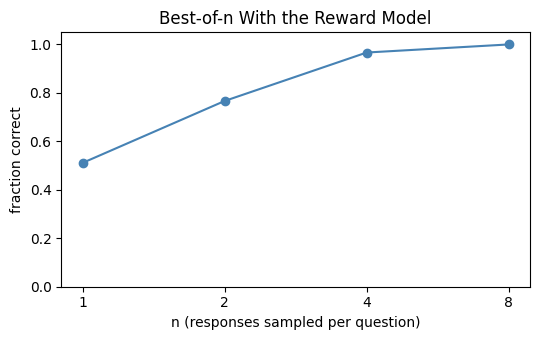

In [9]:
def best_of_n_correct_rate(params, n, trials_per_question=150, seed=3):
    rng = np.random.default_rng(seed)
    hits = []
    for verb in VERBS:
        for _ in range(trials_per_question):
            candidates = [sample_response(params, verb, rng) for _ in range(n)]
            best = max(candidates, key=lambda response: reward(verb, response))
            hits.append(is_correct(verb, best))
    return float(np.mean(hits))

ns = [1, 2, 4, 8]
best_of_n_rates = [best_of_n_correct_rate(sft_model, n) for n in ns]
for n, rate in zip(ns, best_of_n_rates):
    print(f"best of {n}: {rate:.1%} correct")

plt.figure(figsize=(5.5, 3.5))
plt.plot(ns, best_of_n_rates, marker='o', color='steelblue')
plt.xscale('log', base=2)
plt.xticks(ns, ns)
plt.ylim(0, 1.05)
plt.xlabel('n (responses sampled per question)')
plt.ylabel('fraction correct')
plt.title('Best-of-n With the Reward Model')
plt.tight_layout()
plt.show()

Sampling more candidates and keeping the best steadily improves the answers, without changing a single weight in the language model. It's a great technique that comes at a real cost of $n$ times the generation work for every response, forever. If we scale to millions of responses, we can see how this no longer becomes a viable option. 

RLHF pays the cost once, during training, and bake the improvement into the weights so one sample is as good as the best of many.

### Step 3: Optimizing the Language Model Against the Reward Model

Here is the update, using the pieces from `rl_primer/02-policy-gradients.ipynb`. Each round consists of:

1. **Roll out**: sample 16 responses per question from the current model, token by token.
2. **Score**: the reward model gives each whole response one number. Subtract $\beta$ times the response's **KL penalty**, which is how far the current model's token probabilities have drifted from the frozen fine-tuned **reference model** (summed as $\log \pi - \log \pi_{\text{ref}}$ over the tokens it sampled).
3. **Compute advantages**: subtract the average score (the **baseline**) so "better than typical" is positive and "worse than typical" is negative.
4. **Update**: call the *same* `train` function with each sampled token's weight set to its response's advantage.

Step 4 is the point of the weight argument from earlier. `rl_primer/02`'s observation that a policy gradient update is "an ordinary classification loss in disguise" holds here as well, because a token from an above-average response gets pushed up as if it were a correct label, and a token from a below-average response gets pushed down.

In [10]:
reference_model = copy_network(sft_model)     # frozen: the KL penalty compares against this

def rollout(params, verb, rng, max_new_tokens=6):
    sequence = ["<pad>"] * CONTEXT_SIZE + ["what", verb, "?", "<bot>"]
    contexts, token_ids, response = [], [], []
    for _ in range(max_new_tokens):
        context = sequence[-CONTEXT_SIZE:]
        probabilities = next_token_probabilities(params, context)
        token_id = int(rng.choice(vocab_size, p=probabilities / probabilities.sum()))
        contexts.append(context)
        token_ids.append(token_id)
        response.append(vocabulary[token_id])
        sequence.append(vocabulary[token_id])
        if vocabulary[token_id] == "<end>":
            break
    return contexts, token_ids, response

def rlhf(start_params, beta, rounds, learning_rate, samples_per_question=16, seed=0):
    params = copy_network(start_params)
    rng = np.random.default_rng(seed)
    history = []
    for _ in range(rounds):
        batch_inputs, batch_targets, batch_weights = [], [], []
        correct_flags, reward_scores, kl_values = [], [], []
        for verb in VERBS:
            rollouts = [rollout(params, verb, rng) for _ in range(samples_per_question)]
            totals = []
            for contexts, token_ids, response in rollouts:
                kl = sum(np.log(next_token_probabilities(params, c)[t] + 1e-12)
                         - np.log(next_token_probabilities(reference_model, c)[t] + 1e-12)
                         for c, t in zip(contexts, token_ids))
                score = reward(verb, response)
                totals.append(score - beta * kl)
                correct_flags.append(is_correct(verb, response))
                reward_scores.append(score)
                kl_values.append(kl)
            totals = np.array(totals)
            advantages = (totals - totals.mean()) / (totals.std() + 1e-8)     # baseline, then rescale
            for (contexts, token_ids, _), advantage in zip(rollouts, advantages):
                for context, token_id in zip(contexts, token_ids):
                    batch_inputs.append(encode(context))
                    batch_targets.append(token_id)
                    batch_weights.append(advantage)
        params = train(params, np.array(batch_inputs).T, np.array(batch_targets),
                       np.array(batch_weights), learning_rate, steps=1)
        history.append((np.mean(correct_flags), np.mean(reward_scores), np.mean(kl_values)))
    return params, np.array(history)

rlhf_model, history = rlhf(sft_model, beta=0.1, rounds=100, learning_rate=0.5)
print(f"Sampled answers that are correct:  fine-tuned {correct_rate(sft_model):.1%}  ->  after RLHF {correct_rate(rlhf_model):.1%}")

Sampled answers that are correct:  fine-tuned 55.6%  ->  after RLHF 99.9%


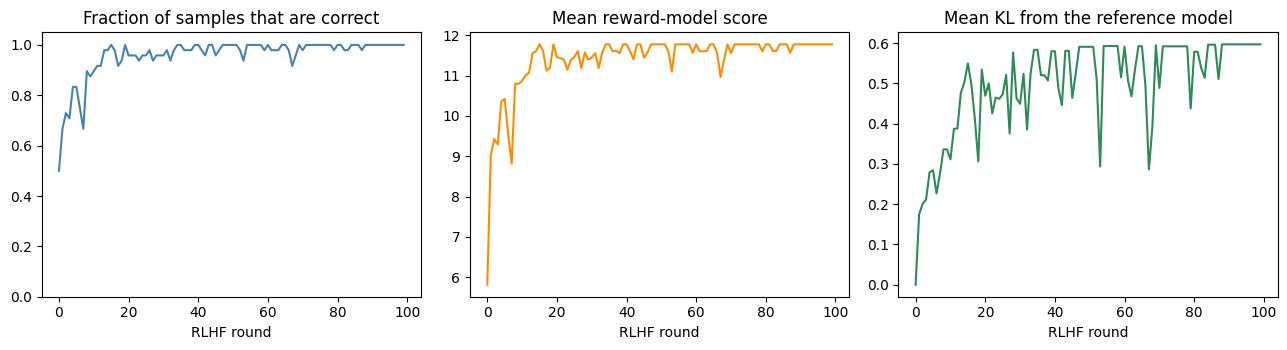

what climbs ?  ->  the robot climbs <end>
what scores ?  ->  the robot scores <end>
what defends ?  ->  the robot defends <end>


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(history[:, 0], color='steelblue')
axes[0].set_title('Fraction of samples that are correct')
axes[0].set_ylim(0, 1.05)
axes[1].plot(history[:, 1], color='darkorange')
axes[1].set_title('Mean reward-model score')
axes[2].plot(history[:, 2], color='seagreen')
axes[2].set_title('Mean KL from the reference model')
for ax in axes:
    ax.set_xlabel('RLHF round')
plt.tight_layout()
plt.show()

rng = np.random.default_rng(1)
for verb in VERBS:
    print(f"what {verb} ?  ->  {' '.join(sample_response(rlhf_model, verb, rng))}")

The correct-answer rate climbs from about half to nearly all of it within about 50 rounds, and the reward model's score rises with it. Nothing told the model what the right answer was. It saw only reward-model scores, and its own best samples gradually pulled the whole distribution toward them. The rightmost chart is the KL penalty's side of the story, showing how far the model has moved from the fine-tuned starting point to get there.

A caveat is needed because of the fact that the KL penalty barely changes the outcome here. The correct answer is already the model's most common output after fine-tuning, so the reward-maximizing behavior is not far from the reference and there is little for the penalty to hold back. In a real system, where the reward model is exploitable in many more directions, the penalty is what keeps the model from sprinting off toward the places where the proxy is wrong, like the rambling response that outscored the correct one.

## What a Real System Adds

The structure above matches how real post-training is built; the differences are scale and engineering.

For one, the reward model itself would be an LLM trained on tens of thousands of human comparisons (if not more), not a 16-unit network on 240 pairs. 

The RL algorithm used is usually PPO (Proximal Policy Optimization), which limits how far a single update can move the policy. There are preference optimization methods that skip this RL loop, however. DPO (Direct Preference Optimization) trains the language model directly on the preference pairs with a loss derived from the same objective, with no separate reward model and no rollouts.

Also, sometimes preferences are not always entirely human. Many labs make use of AI feedback either alongside or even in place of human raters. 

None of that changes the idea this notebook is built around. Pretraining gives a model that can continue text, instruction fine-tuning teaches it the *shape* of a helpful response, and preference feedback pushes it toward the *better* responses within that shape.

## Try It Yourself

**1. Find the reward hack.** Real human raters have biases. A well-documented one is favoring longer answers. Rebuild `preference_pairs` so the rater prefers the *longer* response whenever two sampled responses have different lengths (ignore correctness entirely), retrain the reward model on those pairs, and run `rlhf` with `beta=0.0`. Before you run it, predict what the model's answers will look like. Then read a handful of them. Does the correct-answer rate go up, down, or stay the same? Rerun with `beta=0.5`: does the KL penalty prevent the exploit, or only slow it? Explain in a sentence how this connects to **Reward Hacking** in `rl_primer/README.md`.

**2. A fairer fight for the KL penalty.** Raise `rounds` to 400 and `learning_rate` to 1.0, then compare `beta=0.0` and `beta=1.0` on the third chart (mean KL). Which setting drifts further from the reference model, and what does the model give up in return?

In [12]:
# TODO 1: build "longer is better" preference pairs, retrain the reward model on them,
# run rlhf(sft_model, beta=0.0, ...) and then beta=0.5, and read the sampled answers

# TODO 2: compare the mean-KL curve for beta=0.0 vs beta=1.0 at rounds=400, learning_rate=1.0

## Resources

- Christiano, P. et al. (2017). "Deep Reinforcement Learning from Human Preferences." The paper that introduced learning a reward model from pairwise human comparisons, the same pairwise setup built above (paper).
- Ouyang, L. et al. (2022). "Training Language Models to Follow Instructions with Human Feedback" (the InstructGPT paper). The full SFT -> reward model -> PPO pipeline this notebook shrinks down (paper).
- Rafailov, R. et al. (2023). "Direct Preference Optimization: Your Language Model is Secretly a Reward Model." The RL-free alternative mentioned above (paper).
- [Hugging Face: Illustrating Reinforcement Learning from Human Feedback (RLHF)](https://huggingface.co/blog/rlhf) - a diagram-heavy walkthrough of the same three steps at production scale (instructional).